# 🔗 CRES — LLM Fine-Tuning Notebook
## Character Relation Extraction System

**Model:** `google/flan-t5-base` (250M params — fits on Colab T4 free tier)  
**Dataset:** [`Despina/project-gutenberg-fiction-relations`](https://huggingface.co/datasets/Despina/project-gutenberg-fiction-relations)  
**Task:** Fine-grained relation classification — model predicts the **exact** relation (e.g. `sibling`, `spouse`, `enemy`) not a collapsed category  
**Evaluation:** BERTScore · Weighted F1 · Accuracy

---

### Design Decision: Fine-grained Labels

We train on the **raw relation labels** from the dataset (e.g. `sibling`, `parent-child`, `spouse`, `friend`, `enemy`)  
rather than collapsing them into coarse buckets like `kinship` or `adversarial`.  
A separate **display grouping table** maps fine-grained labels to graph colors for the CRES UI — without losing information.

```
Raw Text  →  NLP Preprocessing  →  Model Tokenization  →  Fine-tuning  →  Evaluation
             (NLTK pipeline)        (flan-t5 tokenizer)    (Seq2SeqTrainer)
             ├─ sent_tokenize
             ├─ word_tokenize
             ├─ POS tagging
             ├─ Lemmatization
             └─ WordNet synsets
```

> **Before running:** Go to `Runtime → Change runtime type → T4 GPU`

## 0. GPU Sanity Check

In [2]:
import subprocess
result = subprocess.run(['nvidia-smi'], capture_output=True, text=True)
if result.returncode == 0:
    print(result.stdout)
else:
    print('⚠️  No GPU detected. Go to Runtime → Change runtime type → T4 GPU')

Thu Oct 15 05:50:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 1. Install Dependencies

**Important:** After installing or changing dependencies, restart the runtime before running the imports cell. The notebook uses PyTorch, so TensorFlow is explicitly disabled to avoid unrelated TensorFlow/protobuf import conflicts.


In [3]:
%%capture
!pip install -q transformers==4.47.0 datasets==3.2.0 evaluate==0.4.3 \
               bert-score==0.3.13 scikit-learn==1.5.2 \
               accelerate==1.2.1 sentencepiece==0.2.0 \
               nltk==3.9.1
print('✅ All packages installed')

## 2. Imports & NLTK Downloads

In [4]:
import os

# Prevent Transformers from importing TensorFlow. This notebook fine-tunes a PyTorch
# model; TensorFlow is not required, and some Colab environments have incompatible
# TensorFlow/protobuf versions that can break Transformers imports.
os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"

import json
import random
import warnings
import numpy as np
import pandas as pd
from collections import Counter
warnings.filterwarnings('ignore')

# ── NLTK ──────────────────────────────────────────────────────────────────────
import nltk
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet
from nltk import pos_tag

nltk.download('punkt',        quiet=True)
nltk.download('punkt_tab',    quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)
nltk.download('wordnet',      quiet=True)
nltk.download('omw-1.4',      quiet=True)

# ── HuggingFace ───────────────────────────────────────────────────────────────
from datasets import load_dataset, DatasetDict
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    DataCollatorForSeq2Seq,
    EarlyStoppingCallback,
)
import torch

# ── Sklearn ────────────────────────────────────────────────────────────────────
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

# ── BERTScore ──────────────────────────────────────────────────────────────────
from bert_score import score as bert_score_fn

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'🖥️  Device: {DEVICE}')
if DEVICE == 'cuda':
    print(f'    GPU: {torch.cuda.get_device_name(0)}')
    print(f'    VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

🖥️  Device: cuda
    GPU: Tesla T4
    VRAM: 15.6 GB


## 3. Configuration

In [5]:
# ─────────────────────────────────────────────────────────────────────────────
# CONFIG — edit these before the final run
# ─────────────────────────────────────────────────────────────────────────────

MODEL_CHECKPOINT  = 'google/flan-t5-base'
DATASET_ID        = 'Despina/project-gutenberg-fiction-relations'
OUTPUT_DIR        = '/content/cres-flan-t5-ft'
FINAL_MODEL_DIR   = '/content/cres-flan-t5-final'

# IMPORTANT: never append the entire 431-label inventory to the input prompt.
# The passage and entity pair must remain visible after tokenization.
MAX_INPUT_LEN     = 384
MAX_TARGET_LEN    = 32
TRAIN_BATCH_SIZE  = 4
EVAL_BATCH_SIZE   = 8
GRAD_ACCUM_STEPS  = 8     # effective batch = 32
LEARNING_RATE     = 5e-5
NUM_EPOCHS        = 3
WARMUP_RATIO      = 0.1
WEIGHT_DECAY      = 0.01

# Set 0.01 and NUM_EPOCHS=1 for a quick smoke test first; restore 1.0 for final run.
TRAIN_FRACTION    = 1.0

print('✅ Config loaded')
print(f'   Model      : {MODEL_CHECKPOINT}')
print(f'   Dataset    : {DATASET_ID}')
print(f'   Epochs     : {NUM_EPOCHS}')
print(f'   Batch size : {TRAIN_BATCH_SIZE} (x{GRAD_ACCUM_STEPS} grad accum = {TRAIN_BATCH_SIZE * GRAD_ACCUM_STEPS} effective)')
print('   Precision  : FP32 (FP16 produced NaN in the diagnostic forward pass)')


✅ Config loaded
   Model      : google/flan-t5-base
   Dataset    : Despina/project-gutenberg-fiction-relations
   Epochs     : 3
   Batch size : 4 (x8 grad accum = 32 effective)
   Precision  : FP32 (FP16 produced NaN in the diagnostic forward pass)


## 4. Load Dataset & Discover Labels

In [6]:
print(f'📦 Loading dataset: {DATASET_ID} ...')
raw_ds = load_dataset(DATASET_ID)

# Keep only examples with a usable relation label and both entity arguments.
# Rows with missing relation/entity values cannot supervise relation extraction:
# they would otherwise become the literal target "none" and prompts containing "None".
def has_valid_relation_example(example):
    relation = example.get("relation")
    entity1 = example.get("entity1")
    entity2 = example.get("entity2")
    return all(
        isinstance(value, str) and value.strip()
        for value in (relation, entity1, entity2)
    )

original_sizes = {split: len(raw_ds[split]) for split in raw_ds}
raw_ds = raw_ds.filter(
    has_valid_relation_example,
    desc="Filtering rows missing relation/entity labels"
)

print("\n📊 Dataset sizes after filtering invalid examples:")
for split in raw_ds:
    removed = original_sizes[split] - len(raw_ds[split])
    print(f"  {split}: {len(raw_ds[split]):,} valid rows (removed {removed:,})")

if len(raw_ds["train"]) == 0:
    raise ValueError("No valid training rows remain after filtering.")

print("\n📊 Sample valid row (train[0]):")
sample = raw_ds["train"][0]
for k, v in sample.items():
    val_str = str(v)[:120] + ("..." if len(str(v)) > 120 else "")
    print(f"  {k:20s}: {val_str}")


📦 Loading dataset: Despina/project-gutenberg-fiction-relations ...


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00003.parquet:   0%|          | 0.00/244M [00:00<?, ?B/s]

data/train-00001-of-00003.parquet:   0%|          | 0.00/244M [00:00<?, ?B/s]

data/train-00002-of-00003.parquet:   0%|          | 0.00/244M [00:00<?, ?B/s]

...

Generating test split:   0%|          | 0/8144 [00:00<?, ? examples/s]

Filtering rows missing relation/entity labels:   0%|          | 0/146579 [00:00<?, ? examples/s]

Filtering rows missing relation/entity labels:   0%|          | 0/8143 [00:00<?, ? examples/s]

Filtering rows missing relation/entity labels:   0%|          | 0/8144 [00:00<?, ? examples/s]


📊 Dataset sizes after filtering invalid examples:
  train: 114,871 valid rows (removed 31,708)
  validation: 6,425 valid rows (removed 1,718)
  test: 6,339 valid rows (removed 1,805)

📊 Sample valid row (train[0]):
  text                : Then Lambikin could not think what to do, for he did not wish to be eaten just then. So he said to the lion:

    “Lam...
  entity1             : Lambikin
  entity2             : lion
  entity1Type         : PER
  entity2Type         : PER
  relation            : enemy_of
  prompt_0_shot       : Given the following context:
"Then Lambikin could not think what to do, for he did not wish to be eaten just then. So he...
  prompt_2_shot       : Sentence: "But Mr. Faversham and I talk of furnishing it before long. You are, I believe, acquainted with Mr. Faversham?...
  prompt_5_shot       : Sentence: ""

Kettering nodded without paying much attention. He was profoundly uninterested in Claud Ambrose and the ...


In [7]:
# ── Discover valid fine-grained labels from training examples ─────────────────
train_relations = raw_ds["train"]["relation"]
label_counts = Counter(
    relation.strip().lower()
    for relation in train_relations
    if isinstance(relation, str) and relation.strip()
)

print(f'📈 Relation distribution in train split ({sum(label_counts.values()):,} valid examples):')
df_dist = pd.DataFrame(label_counts.most_common(), columns=["relation", "count"])
df_dist["pct"] = (df_dist["count"] / df_dist["count"].sum() * 100).round(1)
print(df_dist.to_string(index=False))

# Preserve all observed fine-grained labels; do not collapse labels during training.
ALL_FINE_LABELS = sorted(label_counts.keys())
if not ALL_FINE_LABELS:
    raise ValueError("No valid relation labels found in the training split.")

print(f'\n🏷️ Fine-grained relation types: {len(ALL_FINE_LABELS)}')
for lbl in ALL_FINE_LABELS:
    print(f'  {lbl!r}')


📈 Relation distribution in train split (114,871 valid examples):
                                           relation  count  pct
                                       companion_of  33524 29.2
                                        relative_of  10704  9.3
                                           child_of   6884  6.0
                                           lover_of   5342  4.7
                                          friend_of   5313  4.6
                                         sibling_of   5065  4.4
                                          spouse_of   5021  4.4
                                           enemy_of   4833  4.2
                                           rival_of   4358  3.8
                                   parent_father_of   3434  3.0
                                   parent_mother_of   2605  2.3
                                       protector_of   2466  2.1
                                          travel_to   2329  2.0
                                       

## 5. Display Grouping (For CRES UI Only)

This section defines a **display-only** coarse grouping for graph edge colors in the CRES UI.  
The **model is never trained on these coarse labels** — it learns and predicts fine-grained labels.  
This mapping is saved alongside the model for the frontend to consume.

> Edit this after running cell 4 — use the actual labels printed above.

In [8]:
# Display-only mapping for the CRES UI. This does not affect training labels.
# Only assign a coarse group when the mapping is intentional and defensible.
DISPLAY_GROUP = {
    'sibling_of': 'kinship',
    'relative_of': 'kinship',
    'child_of': 'kinship',
    'parent_father_of': 'kinship',
    'parent_mother_of': 'kinship',
    'spouse_of': 'kinship',
    'lover_of': 'romantic',
    'friend_of': 'alliance',
    'companion_of': 'alliance',
    'ally_of': 'alliance',
    'enemy_of': 'adversarial',
    'rival_of': 'adversarial',
    'employer_of': 'hierarchical',
    'mentor_of': 'hierarchical',
}

def get_display_group(fine_label: str) -> str:
    """Return explicit coarse group or 'other' when not manually mapped."""
    return DISPLAY_GROUP.get(str(fine_label).lower().strip(), 'other')

print('Explicitly mapped fine labels:', len(DISPLAY_GROUP))
print('All other labels display as other, but are NOT treated as equivalent in fine-grained evaluation.')


Explicitly mapped fine labels: 14
All other labels display as other, but are NOT treated as equivalent in fine-grained evaluation.


## 6. NLP Preprocessing Pipeline

Required preprocessing steps applied to text before model tokenization:
- **Sentence Boundary Identification** — `nltk.sent_tokenize`
- **Tokenization** — `nltk.word_tokenize`
- **POS Tagging** — `nltk.pos_tag` (Penn Treebank tags, compulsory)
- **Lemmatization** — `WordNetLemmatizer` (POS-aware)
- **Semantic Analysis** — WordNet synsets for content words (compulsory)

In [9]:
lemmatizer = WordNetLemmatizer()

def penn_to_wordnet_pos(penn_tag: str) -> str:
    """Convert Penn Treebank POS tag to WordNet POS for accurate lemmatization."""
    if penn_tag.startswith('J'):
        return wordnet.ADJ
    elif penn_tag.startswith('V'):
        return wordnet.VERB
    elif penn_tag.startswith('N'):
        return wordnet.NOUN
    elif penn_tag.startswith('R'):
        return wordnet.ADV
    return wordnet.NOUN  # default fallback


def nlp_preprocess(text: str) -> dict:
    """
    Full NLP preprocessing pipeline (all required steps).

    Returns:
        sentences  : List[str]          — sentence boundary detection output
        tokens     : List[List[str]]    — word tokens per sentence
        pos_tags   : List[List[tuple]]  — (token, POS_tag) per sentence
        lemmas     : List[List[str]]    — POS-aware lemmas per sentence
        synset_map : dict               — {token: [top-3 WordNet synset names]}
        clean_text : str                — lemmatized lowercase flat text
    """
    # 1. Sentence Boundary Identification
    sentences = sent_tokenize(text)

    # 2. Tokenization
    tokens = [word_tokenize(s) for s in sentences]

    # 3. POS Tagging (compulsory)
    pos_tags = [pos_tag(sent_tokens) for sent_tokens in tokens]

    # 4. Lemmatization (POS-aware)
    lemmas = [
        [lemmatizer.lemmatize(tok, pos=penn_to_wordnet_pos(tag))
         for tok, tag in sent_tagged]
        for sent_tagged in pos_tags
    ]

    # 5. Semantic Analysis via WordNet (compulsory)
    synset_map = {}
    for sent_lemmas in lemmas:
        for lem in sent_lemmas:
            if lem.isalpha() and len(lem) > 2 and lem not in synset_map:
                syns = wordnet.synsets(lem)
                if syns:
                    synset_map[lem] = [s.name() for s in syns[:3]]

    clean_text = ' '.join(
        lem.lower()
        for sent_lemmas in lemmas
        for lem in sent_lemmas
        if lem.isalpha()
    )

    return {
        'sentences' : sentences,
        'tokens'    : tokens,
        'pos_tags'  : pos_tags,
        'lemmas'    : lemmas,
        'synset_map': synset_map,
        'clean_text': clean_text,
    }


# ── Demo on one example ───────────────────────────────────────────────────────
demo_text = raw_ds['train'][0]['text']
demo_out  = nlp_preprocess(demo_text[:400])

print('=== NLP Preprocessing Demo ===')
print(f'\n📝 Input text (first 200 chars):\n  {demo_text[:200]}...')
print(f'\n📌 Sentences detected: {len(demo_out["sentences"])}')
for i, s in enumerate(demo_out['sentences'][:2]):
    print(f'  [{i}] {s[:100]}')

print(f'\n🔠 Tokens (sent 0, first 10): {demo_out["tokens"][0][:10]}')
print(f'\n🏷️  POS tags (sent 0, first 10): {demo_out["pos_tags"][0][:10]}')
print(f'\n🌿 Lemmas (sent 0, first 10):  {demo_out["lemmas"][0][:10]}')

synset_sample = list(demo_out['synset_map'].items())[:5]
print(f'\n🔍 WordNet Synsets (sample):')
for word, syns in synset_sample:
    print(f'  {word:15s} → {syns}')

=== NLP Preprocessing Demo ===

📝 Input text (first 200 chars):
  Then Lambikin could not think what to do, for he did not wish to be eaten just then. So he said to the lion:

    “Lambikin goes to Grannikin,      Where fatter he will grow,      Then you may eat h...

📌 Sentences detected: 2
  [0] Then Lambikin could not think what to do, for he did not wish to be eaten just then.
  [1] So he said to the lion:

    “Lambikin goes to Grannikin,      Where fatter he will grow,      The

🔠 Tokens (sent 0, first 10): ['Then', 'Lambikin', 'could', 'not', 'think', 'what', 'to', 'do', ',', 'for']

🏷️  POS tags (sent 0, first 10): [('Then', 'RB'), ('Lambikin', 'NNP'), ('could', 'MD'), ('not', 'RB'), ('think', 'VB'), ('what', 'WP'), ('to', 'TO'), ('do', 'VB'), (',', ','), ('for', 'IN')]

🌿 Lemmas (sent 0, first 10):  ['Then', 'Lambikin', 'could', 'not', 'think', 'what', 'to', 'do', ',', 'for']

🔍 WordNet Synsets (sample):
  Then            → ['then.n.01', 'then.s.01', 'then.r.01']
  not        

## 7. Build Instruction Prompt

Do **not** list the entire set of relation labels in the input. The 431-label list expanded the prompt to 1,960 tokens and was truncated at 256 tokens, removing both `Passage:` and `Relationship:`. This version keeps the task and entity pair first and the passage visible. The target label remains the dataset's original fine-grained label.


In [10]:
def build_prompt(text: str, entity1: str, entity2: str) -> str:
    """Build a compact prompt that preserves both entity names and passage context."""
    return (
        "Task: Identify the directed semantic relationship from Entity 1 to Entity 2. "
        "Use the literary passage as evidence. Return only one fine-grained relation label "
        "in the dataset's label format.\n"
        f"Entity 1: {entity1}\n"
        f"Entity 2: {entity2}\n"
        f"Passage: {text.strip()}"
    )

# Demo: inspect the actual input, not just the first 700 characters.
demo_row = raw_ds['train'][0]
demo_prompt = build_prompt(demo_row['text'], demo_row['entity1'], demo_row['entity2'])
print('=== Compact Prompt Demo ===')
print(demo_prompt[:1200])
print(f'\nGold label: {demo_row["relation"]!r}')
print('Prompt token count:', len(tokenizer(demo_prompt, truncation=False)['input_ids']) if 'tokenizer' in globals() else 'tokenizer loads in the next section')


=== Compact Prompt Demo ===
Task: Identify the directed semantic relationship from Entity 1 to Entity 2. Use the literary passage as evidence. Return only one fine-grained relation label in the dataset's label format.
Entity 1: Lambikin
Entity 2: lion
Passage: Then Lambikin could not think what to do, for he did not wish to be eaten just then. So he said to the lion:

    “Lambikin goes to Grannikin,      Where fatter he will grow,      Then you may eat him so.”

 The lion wanted a very fat lamb to eat, so he let Lambikin go on his way, but he said:

“Be sure to come back this way, Lambikin.”

Lambikin frolicked along on his teetery legs a little farther, when he suddenly saw a great vulture, with a huge bill, flying toward him.

 “I will eat you, Lambikin,” said the vulture.

 Now Lambikin was not ready to be eaten yet, so he said to the vulture:

    “Lambikin goes to Grannikin,      Where fatter he will grow,      Then you may eat him so.”

Gold label: 'enemy_of'
Prompt token count:

## 8. Tokenize Dataset

In [11]:
print(f'⬇️  Loading tokenizer: {MODEL_CHECKPOINT}')
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)
print(f'✅ Tokenizer loaded  |  vocab size: {tokenizer.vocab_size:,}')

⬇️  Loading tokenizer: google/flan-t5-base


tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

✅ Tokenizer loaded  |  vocab size: 32,100


In [12]:
def preprocess_for_model(batch):
    """Tokenize compact contextual inputs and normalized fine-grained target labels."""
    inputs = [
        build_prompt(t, e1, e2)
        for t, e1, e2 in zip(batch['text'], batch['entity1'], batch['entity2'])
    ]
    targets = [str(r).lower().strip() for r in batch['relation']]

    model_inputs = tokenizer(
        inputs,
        max_length=MAX_INPUT_LEN,
        padding=False,
        truncation=True,
    )
    labels = tokenizer(
        text_target=targets,
        max_length=MAX_TARGET_LEN,
        padding=False,
        truncation=True,
    )
    labels['input_ids'] = [
        [(token if token != tokenizer.pad_token_id else -100) for token in label]
        for label in labels['input_ids']
    ]
    model_inputs['labels'] = labels['input_ids']
    return model_inputs

print('🔄 Tokenizing dataset...')
ds = raw_ds
if TRAIN_FRACTION < 1.0:
    n_train = max(1, int(len(ds['train']) * TRAIN_FRACTION))
    # Keep smoke-test validation short too; restore full data by setting TRAIN_FRACTION=1.0.
    n_val = min(1000, len(ds['validation']))
    ds = DatasetDict({
        'train': ds['train'].select(range(n_train)),
        'validation': ds['validation'].select(range(n_val)),
        'test': ds['test'],
    })
    print(f'   Using {TRAIN_FRACTION*100:.2f}% of train: {n_train:,} examples')

tokenized_ds = ds.map(
    preprocess_for_model,
    batched=True,
    batch_size=64,
    remove_columns=ds['train'].column_names,
    desc='Tokenizing',
)

print('\n✅ Tokenization complete')
for split in tokenized_ds:
    print(f'   {split:10s}: {len(tokenized_ds[split]):,}')

# Critical preflight: verify that truncation did not cut off the passage marker.
probe_input = tokenizer.decode(tokenized_ds['train'][0]['input_ids'], skip_special_tokens=True)
probe_target_ids = [x for x in tokenized_ds['train'][0]['labels'] if x != -100]
probe_target = tokenizer.decode(probe_target_ids, skip_special_tokens=True)
print('\n=== TOKENIZATION PREFLIGHT ===')
print('Source tokens:', len(tokenized_ds['train'][0]['input_ids']))
print('Passage marker retained:', 'Passage:' in probe_input)
print('Entity 1 marker retained:', 'Entity 1:' in probe_input)
print('Entity 2 marker retained:', 'Entity 2:' in probe_input)
print('Target:', repr(probe_target))
print('Decoded source preview:', probe_input[:700])
assert 'Passage:' in probe_input, 'Prompt truncation removed the passage. Reduce prompt overhead or increase MAX_INPUT_LEN.'
assert 'Entity 1:' in probe_input and 'Entity 2:' in probe_input, 'Prompt truncation removed entity markers.'
assert probe_target, 'Target label tokenization produced an empty target.'


🔄 Tokenizing dataset...


Tokenizing:   0%|          | 0/114871 [00:00<?, ? examples/s]

Tokenizing:   0%|          | 0/6425 [00:00<?, ? examples/s]

Tokenizing:   0%|          | 0/6339 [00:00<?, ? examples/s]


✅ Tokenization complete
   train     : 114,871
   validation: 6,425
   test      : 6,339

=== TOKENIZATION PREFLIGHT ===
Source tokens: 270
Passage marker retained: True
Entity 1 marker retained: True
Entity 2 marker retained: True
Target: 'enemy_of'
Decoded source preview: Task: Identify the directed semantic relationship from Entity 1 to Entity 2. Use the literary passage as evidence. Return only one fine-grained relation label in the dataset's label format. Entity 1: Lambikin Entity 2: lion Passage: Then Lambikin could not think what to do, for he did not wish to be eaten just then. So he said to the lion: “Lambikin goes to Grannikin, Where fatter he will grow, Then you may eat him so.” The lion wanted a very fat lamb to eat, so he let Lambikin go on his way, but he said: “Be sure to come back this way, Lambikin.” Lambikin frolicked along on his teetery legs a little farther, when he suddenly saw a great vulture, with a huge bill, flying toward him. “I will 


## 9. Load Model

In [13]:
print(f'⬇️  Loading model: {MODEL_CHECKPOINT}')
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_CHECKPOINT)
model = model.to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable    = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'✅ Model loaded')
print(f'   Total params    : {total_params/1e6:.1f}M')
print(f'   Trainable params: {trainable/1e6:.1f}M')

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model, pad_to_multiple_of=8)

⬇️  Loading model: google/flan-t5-base


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/990M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

✅ Model loaded
   Total params    : 247.6M
   Trainable params: 247.6M


## 10. Define Training Arguments

In [14]:
training_args = Seq2SeqTrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=NUM_EPOCHS,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM_STEPS,
    learning_rate=LEARNING_RATE,
    warmup_ratio=WARMUP_RATIO,
    weight_decay=WEIGHT_DECAY,
    predict_with_generate=True,
    generation_max_length=MAX_TARGET_LEN,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='eval_loss',
    greater_is_better=False,
    logging_steps=50,
    report_to='none',
    seed=SEED,
    fp16=False,   # IMPORTANT: measured FP16-autocast loss was NaN; use FP32 first.
    bf16=False,
    dataloader_num_workers=2,
    save_total_limit=2,
)
print('✅ Training arguments configured with FP32 precision')


✅ Training arguments configured with FP32 precision


## 11. Train

In [15]:
trainer = Seq2SeqTrainer(
    model         = model,
    args          = training_args,
    train_dataset = tokenized_ds['train'],
    eval_dataset  = tokenized_ds['validation'],
    tokenizer     = tokenizer,
    data_collator = data_collator,
    callbacks     = [EarlyStoppingCallback(early_stopping_patience=2)],
)

print('🚀 Starting fine-tuning...')
print(f'   Effective batch size : {TRAIN_BATCH_SIZE * GRAD_ACCUM_STEPS}')
print(f'   Steps per epoch      : ~{len(tokenized_ds["train"]) // (TRAIN_BATCH_SIZE * GRAD_ACCUM_STEPS)}')
print()

train_result = trainer.train()

print('\n✅ Training complete!')
print(f'   Train runtime      : {train_result.metrics["train_runtime"]:.1f}s')
print(f'   Train samples/sec  : {train_result.metrics["train_samples_per_second"]:.1f}')
print(f'   Final train loss   : {train_result.metrics["train_loss"]:.4f}')

🚀 Starting fine-tuning...
   Effective batch size : 32
   Steps per epoch      : ~3589



huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
Passing a tuple of `past_key_values` is deprecated and will be removed in Transformers v4.48.0. You should pass an instance of `EncoderDecoderCache` instead, e.g. `past_key_values=EncoderDecoderCache.from_legacy_cache(past_key_values)`.


Epoch,Training Loss,Validation Loss
1,0.368700,0.306636
2,0.302000,0.269851


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The 


✅ Training complete!
   Train runtime      : 25839.3s
   Train samples/sec  : 13.3
   Final train loss   : 0.4243


## 12. Save Fine-Tuned Model

In [16]:
trainer.save_model(FINAL_MODEL_DIR)
tokenizer.save_pretrained(FINAL_MODEL_DIR)

# Save fine-grained label list and display grouping for CRES backend/frontend
meta = {
    'fine_labels'   : ALL_FINE_LABELS,
    'display_groups': DISPLAY_GROUP,
}
with open(os.path.join(FINAL_MODEL_DIR, 'cres_label_meta.json'), 'w') as f:
    json.dump(meta, f, indent=2)

print(f'✅ Model saved to: {FINAL_MODEL_DIR}')
print(f'   Fine-grained labels : {len(ALL_FINE_LABELS)}')
!ls -lh {FINAL_MODEL_DIR}

✅ Model saved to: /content/cres-flan-t5-final
   Fine-grained labels : 431


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


total 948M
-rw-r--r-- 1 root root 1.6K Oct 15 13:03 config.json
-rw-r--r-- 1 root root 8.0K Oct 15 13:04 cres_label_meta.json
-rw-r--r-- 1 root root  142 Oct 15 13:03 generation_config.json
-rw------- 1 root root 945M Oct 15 13:04 model.safetensors
-rw-r--r-- 1 root root 2.5K Oct 15 13:04 special_tokens_map.json
-rw-r--r-- 1 root root 774K Oct 15 13:04 spiece.model
-rw-r--r-- 1 root root  21K Oct 15 13:04 tokenizer_config.json
-rw-r--r-- 1 root root 2.4M Oct 15 13:04 tokenizer.json
-rw-r--r-- 1 root root 5.8K Oct 15 13:04 training_args.bin


## 13. Inference Helper

In [17]:
def predict_relation(text: str, entity1: str, entity2: str,
                     model=model, tokenizer=tokenizer) -> dict:
    """Predict a raw fine-grained relation; never silently replace invalid output."""
    prompt = build_prompt(text, entity1, entity2)
    inputs = tokenizer(
        prompt,
        return_tensors='pt',
        max_length=MAX_INPUT_LEN,
        truncation=True,
    ).to(DEVICE)

    model.eval()
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=MAX_TARGET_LEN,
            num_beams=4,
        )

    fine_label = tokenizer.decode(outputs[0], skip_special_tokens=True).strip().lower()
    valid_label = fine_label in ALL_FINE_LABELS
    return {
        'fine_label': fine_label,
        'valid_label': valid_label,
        'display_group': get_display_group(fine_label),
    }

print('=== Inference Sanity Check (5 validation examples) ===')
val_samples = raw_ds['validation'].select(range(min(5, len(raw_ds['validation']))))
for row in val_samples:
    result = predict_relation(row['text'], row['entity1'], row['entity2'])
    gold = str(row['relation']).lower().strip()
    match = '✅' if result['fine_label'] == gold else '❌'
    print(f"{match} {row['entity1']} ↔ {row['entity2']}")
    print(f"   Pred: {result['fine_label']!r} | valid label: {result['valid_label']}")
    print(f"   Gold: {gold!r}")
    print(f"   Text: {row['text'][:160]}...")


=== Inference Sanity Check (5 validation examples) ===
✅ William ↔ his Gipsy
   Pred: 'lover_of' | valid label: True
   Gold: 'lover_of'
   Text: "There's one comfort," she said to Paul--"he'll never have any money to marry on, that I _am_ sure of. And so she'll save him that way. "

So she took cheer. ...
❌ Jai Singh ↔ Finnerty
   Pred: 'rival_of' | valid label: True
   Gold: 'enemy_of'
   Text: In his foul endeavour Jai Singh had lost defence. A hand took him by the left wrist, a corkscrew twist broke his hold, and he commenced to go over forward in to...
✅ Isabel ↔ Lady Mount Severn
   Pred: 'relative_of' | valid label: True
   Gold: 'relative_of'
   Text: You----"

Isabel suddenly stopped; for with the word "remember," she also remembered something--the hundred pound note--and what she was saying faltered on he...
✅ her ↔ her companion
   Pred: 'companion_of' | valid label: True
   Gold: 'companion_of'
   Text: During the breathless minutes of her watch she had seen her companion a

## 14. Evaluation — Fine-grained Test Metrics

Fine-grained accuracy and F1 are the primary metrics. Invalid generated labels remain invalid and are counted; they are not silently replaced by a convenient label. Grouped metrics are reported only on examples whose gold and predicted labels both have an explicit, curated display-group mapping, and their coverage is reported.


In [18]:
test_rows        = raw_ds['test']
EVAL_LIMIT       = min(len(test_rows), 500)   # remove cap for full eval

print(f'🔍 Running inference on {EVAL_LIMIT} test examples...')

y_true_fine  = []   # fine-grained gold labels
y_pred_fine  = []   # fine-grained predictions
y_true_group = []   # coarse display group gold
y_pred_group = []   # coarse display group predictions
refs_bscore  = []   # for BERTScore reference
hyps_bscore  = []   # for BERTScore hypothesis

invalid_predictions = 0

for i, row in enumerate(test_rows.select(range(EVAL_LIMIT))):
    gold_fine  = str(row['relation']).lower().strip()
    result     = predict_relation(row['text'], row['entity1'], row['entity2'])
    pred_fine  = result['fine_label']
    invalid_predictions += int(not result['valid_label'])

    y_true_fine.append(gold_fine)
    y_pred_fine.append(pred_fine)
    y_true_group.append(get_display_group(gold_fine))
    y_pred_group.append(get_display_group(pred_fine))
    refs_bscore.append(gold_fine)
    hyps_bscore.append(pred_fine)

    if (i + 1) % 50 == 0:
        print(f'   [{i+1}/{EVAL_LIMIT}]...')

print('\n✅ Inference complete')

🔍 Running inference on 500 test examples...
   [50/500]...
   [100/500]...
   [150/500]...
   [200/500]...
   [250/500]...
   [300/500]...
   [350/500]...
   [400/500]...
   [450/500]...
   [500/500]...

✅ Inference complete


In [19]:
# ── Fine-grained metrics (primary) ─────────────────────────────────────────────
acc_fine = accuracy_score(y_true_fine, y_pred_fine)
f1_fine_w = f1_score(y_true_fine, y_pred_fine, average='weighted', zero_division=0)
f1_fine_m = f1_score(y_true_fine, y_pred_fine, average='macro', zero_division=0)

# Grouped metric is computed ONLY when both gold and prediction have explicit mappings.
# Otherwise mapping every unknown label to 'other' can create a misleadingly high score.
mapped_mask = [
    gold in DISPLAY_GROUP and pred in DISPLAY_GROUP
    for gold, pred in zip(y_true_fine, y_pred_fine)
]
mapped_count = sum(mapped_mask)
group_coverage = mapped_count / len(mapped_mask) if mapped_mask else 0.0

print('=' * 65)
print('CRES Fine-Tuning — Evaluation Results')
print('=' * 65)
print(f'Evaluated examples      : {len(y_true_fine)}')
print(f'Invalid label outputs   : {invalid_predictions} ({invalid_predictions / max(1, len(y_true_fine)):.2%})')
print('\n[ Fine-grained Labels — primary metric ]')
print(f'  Accuracy              : {acc_fine:.4f} ({acc_fine*100:.2f}%)')
print(f'  F1 (weighted)         : {f1_fine_w:.4f}')
print(f'  F1 (macro)            : {f1_fine_m:.4f}')

if mapped_count:
    true_group_mapped = [get_display_group(y_true_fine[i]) for i, ok in enumerate(mapped_mask) if ok]
    pred_group_mapped = [get_display_group(y_pred_fine[i]) for i, ok in enumerate(mapped_mask) if ok]
    acc_group = accuracy_score(true_group_mapped, pred_group_mapped)
    f1_group = f1_score(true_group_mapped, pred_group_mapped, average='weighted', zero_division=0)
    print('\n[ Explicitly mapped display groups — secondary metric ]')
    print(f'  Mapping coverage     : {mapped_count}/{len(mapped_mask)} ({group_coverage:.2%})')
    print(f'  Accuracy (grouped)   : {acc_group:.4f} ({acc_group*100:.2f}%)')
    print(f'  F1 (grouped, weighted): {f1_group:.4f}')
else:
    acc_group = None
    f1_group = None
    print('\nGrouped metrics not reported: no examples have both labels explicitly mapped.')

print('\n--- Per Fine-grained Class Report ---')
print(classification_report(y_true_fine, y_pred_fine, zero_division=0))


CRES Fine-Tuning — Evaluation Results
Evaluated examples      : 500
Invalid label outputs   : 1 (0.20%)

[ Fine-grained Labels — primary metric ]
  Accuracy              : 0.6840 (68.40%)
  F1 (weighted)         : 0.6592
  F1 (macro)            : 0.4012

[ Explicitly mapped display groups — secondary metric ]
  Mapping coverage     : 386/500 (77.20%)
  Accuracy (grouped)   : 0.8238 (82.38%)
  F1 (grouped, weighted): 0.8163

--- Per Fine-grained Class Report ---
                  precision    recall  f1-score   support

 acquaintance_of       0.00      0.00      0.00         1
         ally_of       0.00      0.00      0.00         1
 associated_with       1.00      0.20      0.33         5
     attended_by       1.00      1.00      1.00         1
        based_in       0.00      0.00      0.00         1
     believes_in       0.50      0.33      0.40         3
         born_in       0.50      0.25      0.33         4
          causes       0.00      0.00      0.00         0
        chi

In [20]:
# ── BERTScore ─────────────────────────────────────────────────────────────────
print('📐 Computing BERTScore...')
P, R, F1_bert = bert_score_fn(
    hyps_bscore,
    refs_bscore,
    lang                  = 'en',
    rescale_with_baseline = True,
    verbose               = False,
)
bert_p = P.mean().item()
bert_r = R.mean().item()
bert_f = F1_bert.mean().item()

print(f'  BERTScore Precision : {bert_p:.4f}')
print(f'  BERTScore Recall    : {bert_r:.4f}')
print(f'  BERTScore F1        : {bert_f:.4f}')
print()
print('ℹ️  Note: BERTScore on single/short label strings captures whether wrong')
print('   predictions are semantically close (e.g. sibling vs cousin vs parent-child).')

📐 Computing BERTScore...


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  BERTScore Precision : 0.9261
  BERTScore Recall    : 0.9267
  BERTScore F1        : 0.9260

ℹ️  Note: BERTScore on single/short label strings captures whether wrong
   predictions are semantically close (e.g. sibling vs cousin vs parent-child).


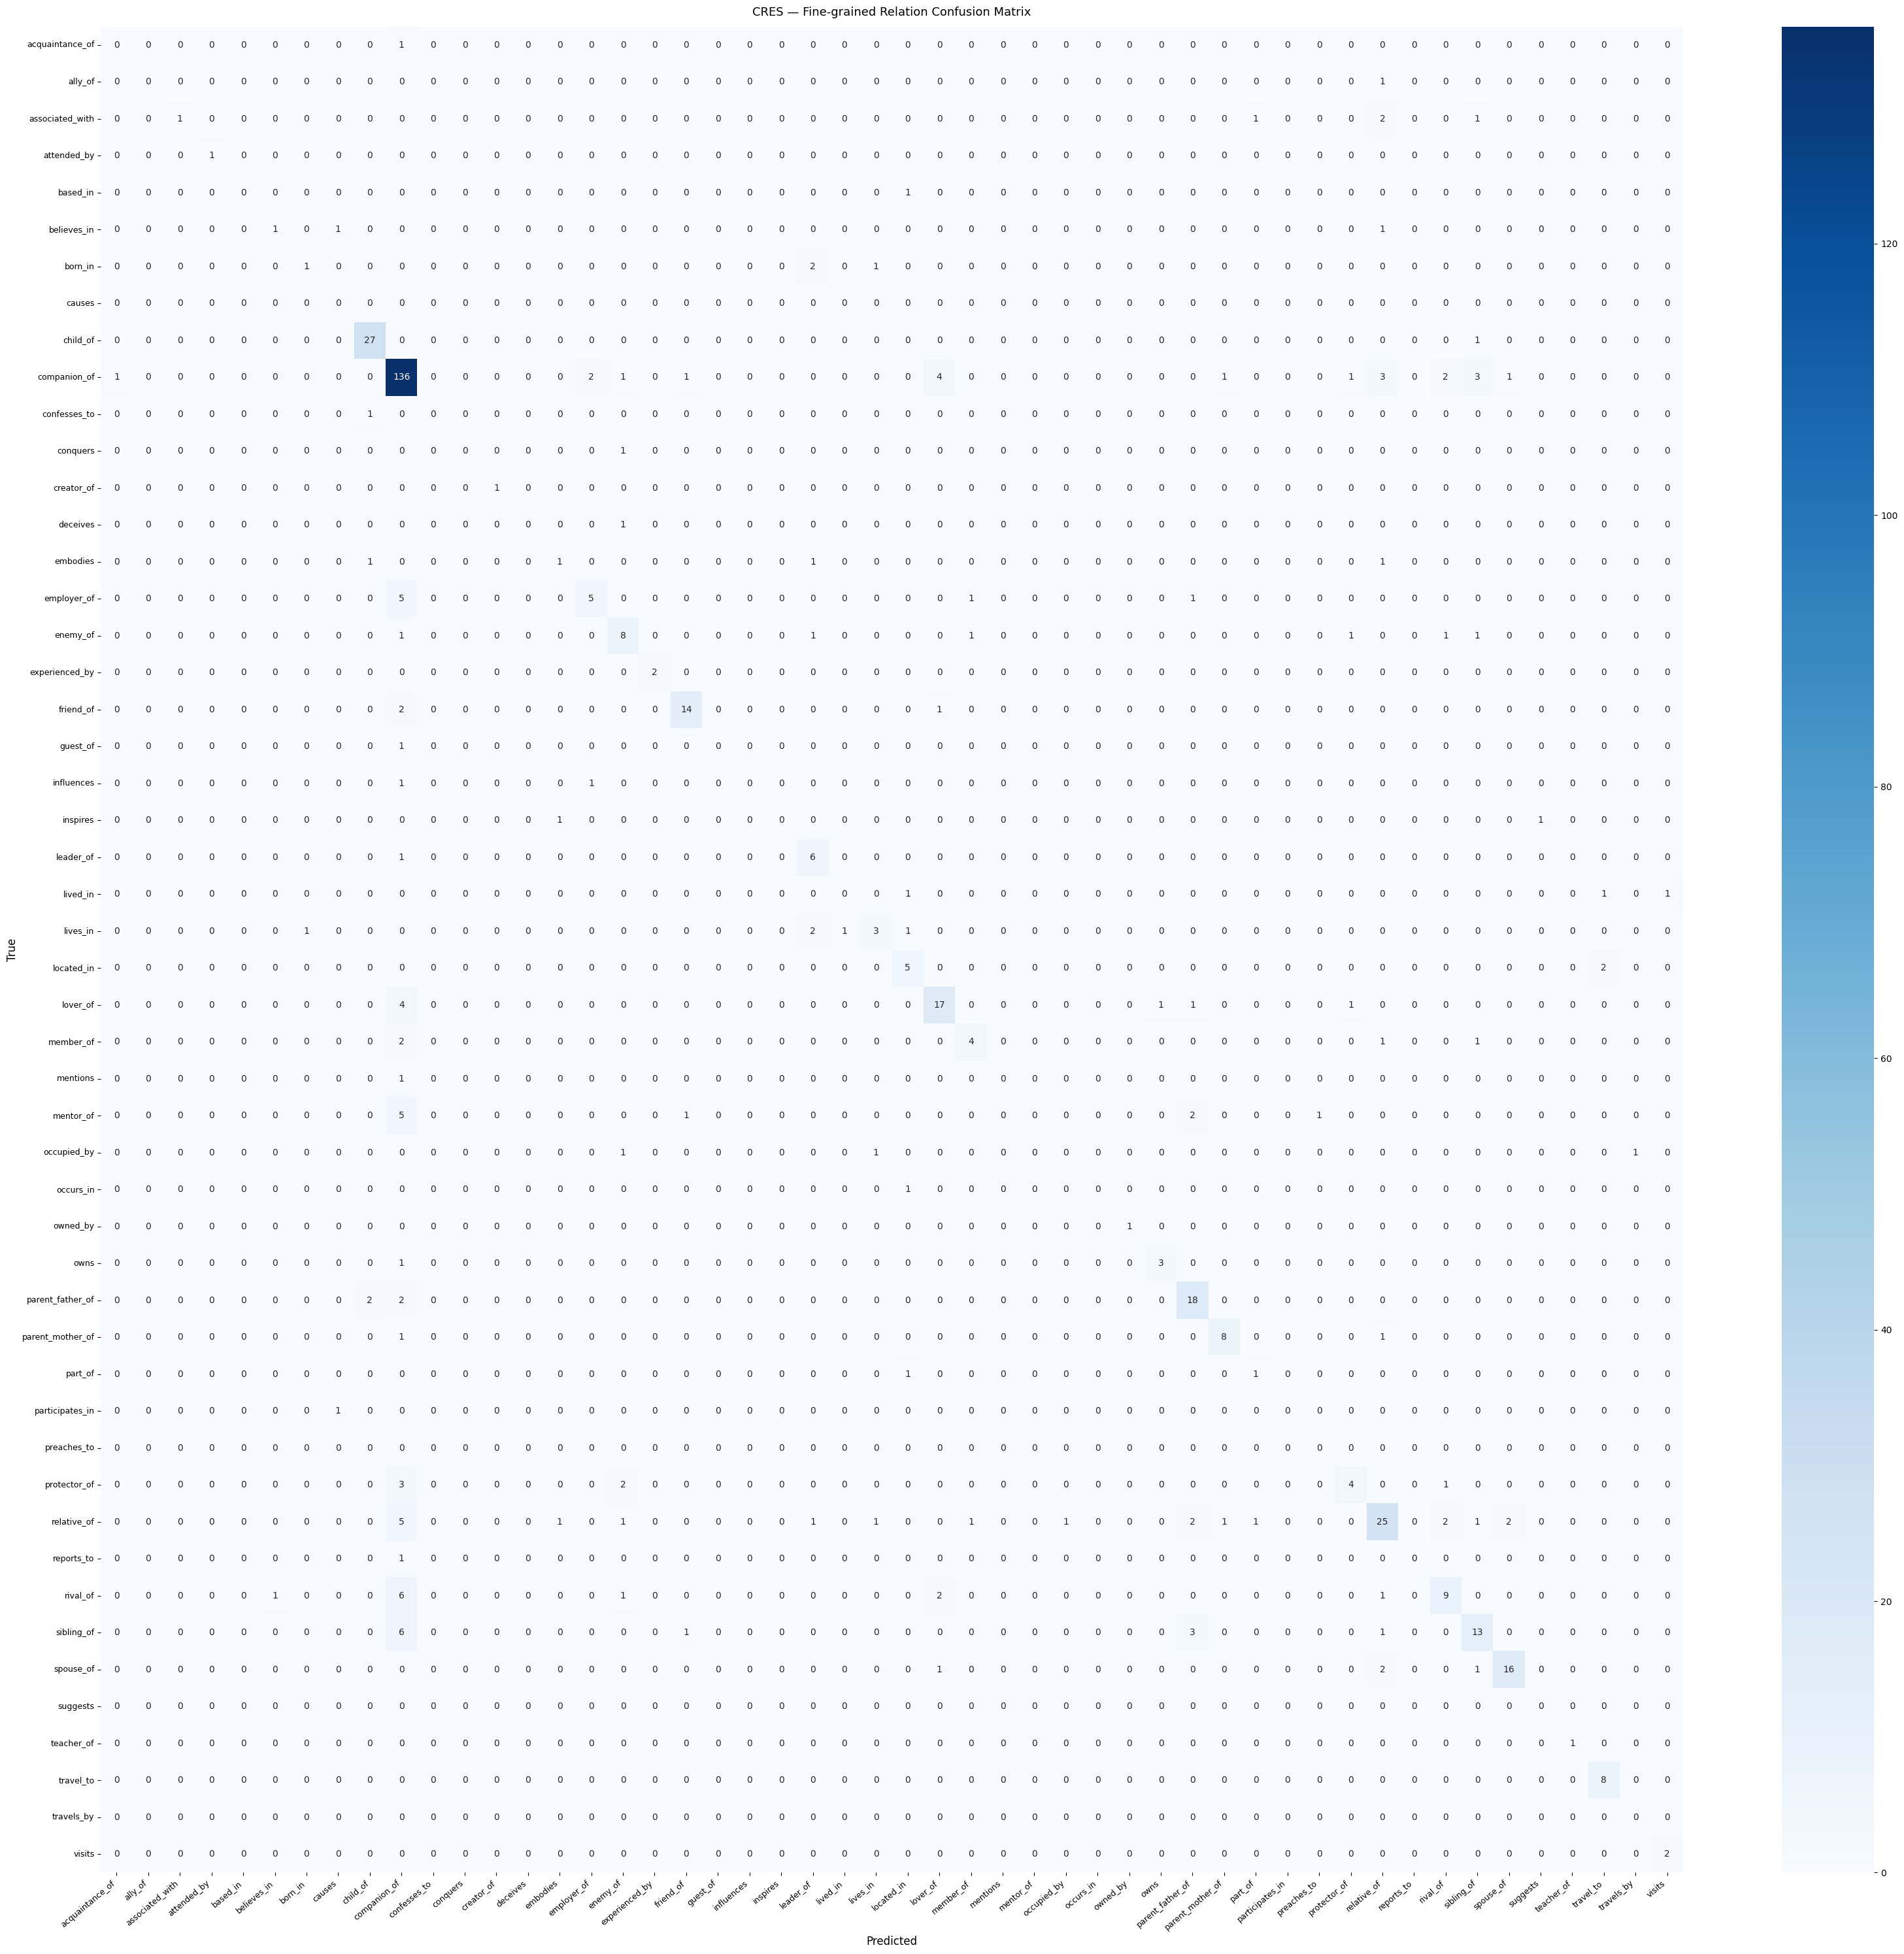

✅ Saved: /content/cres_confusion_matrix.png


In [21]:
# ── Confusion Matrix (fine-grained) ───────────────────────────────────────────
import matplotlib.pyplot as plt
import seaborn as sns

labels_present = sorted(set(y_true_fine + y_pred_fine))
cm = confusion_matrix(y_true_fine, y_pred_fine, labels=labels_present)

fig_h = max(8, len(labels_present) * 0.6)
fig, ax = plt.subplots(figsize=(fig_h + 2, fig_h))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=labels_present, yticklabels=labels_present, ax=ax
)
ax.set_xlabel('Predicted', fontsize=12)
ax.set_ylabel('True', fontsize=12)
ax.set_title('CRES — Fine-grained Relation Confusion Matrix', fontsize=13, pad=12)
plt.xticks(rotation=40, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.savefig('/content/cres_confusion_matrix.png', dpi=150)
plt.show()
print('✅ Saved: /content/cres_confusion_matrix.png')

In [22]:
# ── Save full results JSON ────────────────────────────────────────────────────
summary = {
    'model'                  : MODEL_CHECKPOINT,
    'dataset'                : DATASET_ID,
    'test_examples'          : EVAL_LIMIT,
    'num_fine_labels'        : len(ALL_FINE_LABELS),
    'fine_labels'            : ALL_FINE_LABELS,
    'accuracy_fine'          : round(acc_fine, 4),
    'f1_weighted_fine'       : round(f1_fine_w, 4),
    'f1_macro_fine'          : round(f1_fine_m, 4),
    'accuracy_display_group' : round(acc_group, 4) if acc_group is not None else None,
    'f1_weighted_group'      : round(f1_group, 4) if f1_group is not None else None,
    'invalid_predictions'     : int(invalid_predictions),
    'display_group_coverage'  : round(group_coverage, 4),
    'bertscore_precision'    : round(bert_p, 4),
    'bertscore_recall'       : round(bert_r, 4),
    'bertscore_f1'           : round(bert_f, 4),
}

print('=' * 65)
print('FINAL SUMMARY')
print('=' * 65)
for k, v in summary.items():
    print(f'  {k:28s}: {v}')

with open('/content/cres_eval_results.json', 'w') as f:
    json.dump(summary, f, indent=2)
print('\n✅ Saved: /content/cres_eval_results.json')

FINAL SUMMARY
  model                       : google/flan-t5-base
  dataset                     : Despina/project-gutenberg-fiction-relations
  test_examples               : 500
  num_fine_labels             : 431
  fine_labels                 : ['abducted_by', 'accomplice_of', 'accuser_of', 'accuses', 'acquaintance_of', 'acquaintance_with', 'acquainted_with', 'actor_of', 'addresses', 'addressing', 'admirer_of', 'admires', 'adopted_by', 'adviser_of', 'adviser_to', 'advises', 'advisor_of', 'affected_by', 'affects', 'afraid_of', 'agent_of', 'aids', 'alias_of', 'ally_of', 'ancestor_of', 'annoys', 'appears_to', 'approached_by', 'approves', 'arrived_at', 'arrives_at', 'arrives_in', 'ask_pardon_of', 'asks', 'associate_of', 'associate_with', 'associated_with', 'attacks', 'attempts_to_take', 'attended_by', 'attends', 'audience_of', 'author_of', 'authored_by', 'avoiding', 'avoids', 'aware_of', 'based_in', 'begged', 'believes_in', 'benefactor_of', 'bequeathed_by', 'besieging', 'betrothed_to', 'b

## 15. Download Artifacts

In [23]:
from google.colab import files

files.download('/content/cres_eval_results.json')
files.download('/content/cres_confusion_matrix.png')

# Zip and download model weights (large ~1GB — optional)
DOWNLOAD_MODEL = False
if DOWNLOAD_MODEL:
    !zip -r /content/cres-flan-t5-final.zip {FINAL_MODEL_DIR}
    files.download('/content/cres-flan-t5-final.zip')

print('✅ Downloads triggered')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Downloads triggered


## 16. (Optional) Push to Hugging Face Hub

In [24]:
# from huggingface_hub import login
# login(token='hf_YOUR_TOKEN_HERE')  # hf.co/settings/tokens

# HF_REPO = 'your-username/cres-flan-t5-literary-re'
# model.push_to_hub(HF_REPO)
# tokenizer.push_to_hub(HF_REPO)
# print(f'✅ Pushed to: https://huggingface.co/{HF_REPO}')